# Leak detection — saved-model validation

**Goal:** Load the original trained Stage 1 and Stage 2 `.pt` weights, evaluate the four-probe experiment `1212_1`, and plot **actual leak state (0/1)** against **predicted leak probability (0–1)** over time. Save both the prediction CSV and figure.

**Expected project layout** (notebook can run from `notebooks/` or the project root):

```text
project/
├── data/2026-03-04/
│   ├── DDS1212_1.csv
│   ├── DS1212_1.csv
│   ├── US1212_1.csv
│   └── UUS1212_1.csv
├── models/
│   ├── leak_detect_baseline.pt
│   └── leak_detect_residual.pt
└── notebooks/
    └── leak_probability_validation.ipynb
```

This follows the original notebook's model classes, sensor ordering, normalization (`Re/150`, amplitudes `/50`), coordinates, residual calculation, 40-step windows, and endpoint labels. **No training is performed.** The original notebook used `1212_1` for validation/model selection, so this is a **validation evaluation, not an untouched independent test**.

**Note:** The author did not save a tuned decision threshold in the `.pt` weight files. We use **0.5** for descriptive binary metrics; the main probability plot does not require a threshold.

In [8]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, average_precision_score,
                             roc_auc_score, brier_score_loss)

# USER CONFIGURATION
EXPERIMENT = "1212_1"          # original validation experiment; 1211_1 was training
WINDOW_SIZE = 40
BATCH_SIZE = 64               # reduce to 16 or 32 if memory constrained
THRESHOLD = 0.5               # NOT the author's optimized validation threshold
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROBE_ORDER = ["UUS", "US", "DS", "DDS"]

# Works whether Jupyter's working directory is project/notebooks or project/.
start = Path.cwd().resolve()
candidates = [start, start.parent]
PROJECT_ROOT = next((p for p in candidates
                     if (p / "data" / "2026-03-04").is_dir() and (p / "models").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Cannot find project root from {start}. Expected data/2026-03-04 and models/ "
        "under the working directory or its parent."
    )
DATA_DIR = PROJECT_ROOT / "data" / "2026-03-04"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "validation_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_PATH = MODELS_DIR / "leak_detect_baseline.pt"
RESIDUAL_PATH = MODELS_DIR / "leak_detect_residual.pt"

for path in [BASELINE_PATH, RESIDUAL_PATH] + [DATA_DIR / f"{p}{EXPERIMENT}.csv" for p in PROBE_ORDER]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}")
print("Project:", PROJECT_ROOT)
print("Data:", DATA_DIR)
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)

Project: /home/ubuntu/notebooks/Leak_Detection
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04
Device: cpu
Output: /home/ubuntu/notebooks/Leak_Detection/results/validation_outputs


## 1. Original neural-network architectures

The following class definitions are copied from `GTvate_leak_detect(2).ipynb`, cells 16 and 24, to ensure the saved state dictionaries load with the same parameter names and model behavior.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class BaselineSpectralModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        re_feat_dim=16,
        coord_feat_dim=16
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.re_feat_dim = re_feat_dim
        self.coord_feat_dim = coord_feat_dim

        self.re_embed = nn.Sequential(
            nn.Linear(1, re_feat_dim),
            nn.ReLU()
        )

        self.coord_embed = nn.Sequential(
            nn.Linear(2, coord_feat_dim),
            nn.ReLU()
        )

        self.re_lstm = nn.LSTM(
            input_size=re_feat_dim + coord_feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.re_to_spec = nn.Linear(hidden_dim, Freq)

    def forward(self, X_window, Re_window, coords):

        B, W, P, F = X_window.shape
        assert F == self.Freq

        # Build per-probe inputs in batched form
        re_p = Re_window.unsqueeze(-1).unsqueeze(-1).expand(-1, -1, P, 1)   # (B,W,P,1)
        coord_p = coords.unsqueeze(1).expand(-1, W, -1, -1)                  # (B,W,P,2)

        re_feat = self.re_embed(re_p)                                         # (B,W,P,Cr)
        coord_feat = self.coord_embed(coord_p)                                # (B,W,P,Cc)

        probe_in = torch.cat([re_feat, coord_feat], dim=-1)                   # (B,W,P,Cr+Cc)

        # Move P into batch: (B,W,P,D) -> (B*P,W,D)
        D = probe_in.shape[-1]
        probe_in = probe_in.permute(0, 2, 1, 3).contiguous()                  # (B,P,W,D)
        probe_in = probe_in.view(B * P, W, D)                                 # (B*P,W,D)

        # Shared LSTM over each probe independently
        probe_feats, _ = self.re_lstm(probe_in)                               # (B*P,W,H)

        # Reshape back: (B*P,W,H) -> (B,W,P,H)
        H = probe_feats.shape[-1]
        probe_feats = probe_feats.view(B, P, W, H)                            # (B,P,W,H)
        probe_feats = probe_feats.permute(0, 2, 1, 3).contiguous()            # (B,W,P,H)

        X_hat = self.re_to_spec(probe_feats)                                  # (B,W,P,F)

        return {"baseline": X_hat}

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ProbeFrequencyUpdateBlock(nn.Module):
    def __init__(self, feat_dim, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.feat_dim = feat_dim

        self.gate_mlp = nn.Sequential(
            nn.Linear(2 * feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.out_dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(feat_dim)

    def forward(self, h_pre, return_stats=False):

        B_graph, P, D = h_pre.shape
        assert D == self.feat_dim, f"Expected feat_dim={self.feat_dim}, got {D}"

        hi = h_pre.unsqueeze(2).expand(B_graph, P, P, D)
        hj = h_pre.unsqueeze(1).expand(B_graph, P, P, D)

        diff = hj - hi
        abs_diff = torch.abs(diff)

        edge_feat = torch.cat([diff, abs_diff], dim=-1)
        gate = torch.sigmoid(self.gate_mlp(edge_feat))

        eye = torch.eye(P, device=h_pre.device).view(1, P, P, 1)
        gate = gate * (1.0 - eye)

        msg = diff * gate
        denom = gate.sum(dim=2).clamp_min(1e-6)
        agg = msg.sum(dim=2) / denom

        h_post = self.norm(self.out_dropout(agg))

        if return_stats:
            stats = {
                "gate_mean": gate.mean().detach(),
                "gate_matrix": gate.squeeze(-1).detach(),
                "agg_abs_mean": agg.abs().mean().detach(),
                "agg_norm": agg.norm(dim=-1).mean().detach(),
                "h_post_abs_mean": h_post.abs().mean().detach(),
                "h_post_norm": h_post.norm(dim=-1).mean().detach(),
            }
            return h_post, stats

        return h_post


class ResidualLSTMFrequencyGraphLeakNet(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        tf_hidden_dim=64,
        graph_hidden_dim=64,
        readout_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1,
        weight_temperature=2.0,
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.weight_temperature = weight_temperature


        # Per-probe temporal encoder
        self.lstm = nn.LSTM(
            input_size=Freq,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.0 if num_lstm_layers == 1 else dropout
        )

        # Decode hidden temporal features back into frequency space.
        self.decode_freq = nn.Sequential(
            nn.Linear(hidden_dim, tf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(tf_hidden_dim, Freq)
        )

        self.summary_dim = 3 * Freq

        self.freq_block_dim = 3
        self.readout_block_dim = 6
        self.readout_dim = self.readout_block_dim * Freq 

        # Frequency-wise graph block
        self.gnn = ProbeFrequencyUpdateBlock(
            feat_dim=self.freq_block_dim,
            hidden_dim=graph_hidden_dim,
            dropout=dropout
        )

        # Probe-frequency score head
        self.probe_freq_score_head = nn.Sequential(
            nn.Linear(self.readout_block_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )


        # Optional diagnostic per-probe heads
        self.probe_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.probe_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        # Global heads
        self.global_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.global_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

    def _time_summary(self, x):

        x_mean = x.mean(dim=1)
        x_max = x.max(dim=1).values
        x_last = x[:, -1, :]

        return torch.cat([x_mean, x_max, x_last], dim=-1)

    def _reshape_summary_to_frequency_blocks(self, h_pre, B, P, Freq):
        h_pre_freq = h_pre.view(B, P, 3, Freq)
        h_pre_freq = h_pre_freq.permute(0, 1, 3, 2).contiguous()
        return h_pre_freq

    def _flatten_frequency_readout(self, h_readout_freq, B, P, Freq):

        h_readout = (
            h_readout_freq
            .permute(0, 1, 3, 2)    
            .contiguous()
            .view(B, P, 6 * Freq) 
        )
        return h_readout

    def _flatten_h_post_freq(self, h_post_freq, B, P, Freq):

        h_post = (
            h_post_freq
            .permute(0, 1, 3, 2)   
            .contiguous()
            .view(B, P, 3 * Freq)    
        )
        return h_post

    def _build_global_from_frequency_blocks(self, h_readout_freq):

        B, P, Freq, C = h_readout_freq.shape
        assert C == self.readout_block_dim, (
            f"Expected block dim={self.readout_block_dim}, got {C}"
        )

        # Score each probe-frequency block
        probe_freq_scores = self.probe_freq_score_head(h_readout_freq).squeeze(-1)

        # Independent sigmoid gates
        probe_freq_weights = torch.sigmoid(probe_freq_scores)

        # P-scaled weighted sum across probes
        h_global_freq = torch.sum(
            probe_freq_weights.unsqueeze(-1) * h_readout_freq,
            dim=1
        ) / P

        # Flatten back to (B, 6F)
        h_global = (
            h_global_freq
            .permute(0, 2, 1)
            .contiguous()
            .view(B, self.readout_block_dim * Freq)
        )

        # Diagnostic scalar per frequency
        h_global_scores = torch.sum(
            probe_freq_weights * probe_freq_scores,
            dim=1
        ) / P

        return (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        )

    def forward(
        self,
        residual_window,
        probe_coords=None,
        disable_gnn=False,
        return_gnn_stats=False,
    ):

        B, W, P, Freq = residual_window.shape
        assert Freq == self.Freq, f"Expected Freq={self.Freq}, got {Freq}"

        # Encode each probe independently through the LSTM
        x = residual_window.permute(0, 2, 1, 3).contiguous()
        x = x.view(B * P, W, Freq)

        lstm_out_raw, _ = self.lstm(x)    
        decoded_freq_raw = self.decode_freq(lstm_out_raw)  

        # Build mean / max / last time summary
        decoded_summary_raw = self._time_summary(decoded_freq_raw)
        h_pre = decoded_summary_raw.view(B, P, self.summary_dim)

        # Reshape into frequency-wise blocks
        h_pre_freq = self._reshape_summary_to_frequency_blocks(h_pre, B, P, Freq)

        # Graph each frequency across probes
        gnn_stats = None

        if not disable_gnn:
            h_for_gnn = h_pre_freq.permute(0, 2, 1, 3).contiguous()
            h_for_gnn = h_for_gnn.view(B * Freq, P, self.freq_block_dim)

            if return_gnn_stats:
                h_post_graph, gnn_stats = self.gnn(h_for_gnn, return_stats=True)
            else:
                h_post_graph = self.gnn(h_for_gnn)

            h_post_freq = h_post_graph.view(B, Freq, P, self.freq_block_dim)
            h_post_freq = h_post_freq.permute(0, 2, 1, 3).contiguous()
        else:
            h_post_freq = h_pre_freq

        # Flatten graph output for diagnostics
        h_post = self._flatten_h_post_freq(h_post_freq, B, P, Freq)

        # Build frequency-wise readout
        h_readout_freq = torch.cat([h_pre_freq, h_post_freq], dim=-1)

        # Flatten for optional diagnostic per-probe heads
        h_readout = self._flatten_frequency_readout(h_readout_freq, B, P, Freq)

        # Optional per-probe diagnostics
        probe_leak_logits = self.probe_leak_head(h_readout).squeeze(-1)
        probe_leak_probs = torch.sigmoid(probe_leak_logits)

        probe_mag_raw = self.probe_mag_head(h_readout).squeeze(-1)
        probe_mag_base = F.softplus(probe_mag_raw)

        # Build global vector from frequency-wise probe pooling
        (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        ) = self._build_global_from_frequency_blocks(h_readout_freq)

        # Global leak probability and magnitude
        leak_logit = self.global_leak_head(h_global).squeeze(-1)
        leak_prob = torch.sigmoid(leak_logit)

        mag_base = F.softplus(self.global_mag_head(h_global).squeeze(-1))

        magnitude = mag_base * leak_prob.detach()

        # Reshape LSTM outputs for diagnostics
        H = lstm_out_raw.shape[-1]

        lstm_out = (
            lstm_out_raw
            .view(B, P, W, H)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_freq = (
            decoded_freq_raw
            .view(B, P, W, Freq)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_summary = decoded_summary_raw.view(B, P, self.summary_dim)

        out = {
            # Final predictions
            "leak_logit": leak_logit,      # (B,)
            "leak_prob": leak_prob,        # (B,)
            "magnitude": magnitude,        # (B,)
            "mag_base": mag_base,          # (B,)

            # Main global representation
            "h_global": h_global,              # (B, 6F)
            "h_global_freq": h_global_freq,    # (B, F, 6)
            "h_global_scores": h_global_scores,# (B, F)

            # Frequency-wise graph / pooling diagnostics
            "h_pre_freq": h_pre_freq,                  # (B, P, F, 3)
            "h_post_freq": h_post_freq,                # (B, P, F, 3)
            "h_readout_freq": h_readout_freq,          # (B, P, F, 6)
            "probe_freq_scores": probe_freq_scores,    # (B, P, F)
            "probe_freq_weights": probe_freq_weights,  # (B, P, F)

            # Flattened diagnostics
            "h_pre": h_pre,                  # (B, P, 3F)
            "h_post": h_post,                # (B, P, 3F)
            "h_readout": h_readout,          # (B, P, 6F)

            # LSTM / decoded frequency diagnostics
            "lstm_out": lstm_out,                    # (B, W, P, H)
            "decoded_freq": decoded_freq,            # (B, W, P, F)
            "decoded_summary": decoded_summary,      # (B, P, 3F)

            # Optional per-probe diagnostic heads
            "probe_leak_logits": probe_leak_logits,  # (B, P)
            "probe_leak_probs": probe_leak_probs,    # (B, P)
            "probe_mag_base": probe_mag_base,        # (B, P)
        }

        if return_gnn_stats:
            out["gnn_stats"] = gnn_stats

        return out

## 2. Read and align the four CSV sensor files

- Use the original probe order: **UUS, US, DS, DDS**.
- Use the original frequency column naming (`ǀf...`) and numerical ordering.
- Read `Re`, `Leak Event`, and `Date-Time` from the reference probe, as in the original code.
- Require all four sensors; never pad missing sensors with zeros for evaluation.
- Verify that sensor timestamps and leak labels agree before inference.

In [4]:
PROBE_COORDS = {
    "1212_1": {
        "UUS": [-4.1275, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250], "US": [-0.4572, 0.0250],
        "DS": [0.4572, 0.0250], "DDS": [3.0226, 0.0250],
    },
}
HOLE_SIZES = {"1212_1": 4.0, "1211_1": 2.0}


def read_sensor_csv(path):
    df = pd.read_csv(path, low_memory=False)
    if len(df.columns) == 1:
        raise ValueError(f"Only one column found in {path.name}; check CSV delimiter/format.")
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_experiment(experiment):
    if experiment not in PROBE_COORDS:
        raise ValueError(f"Coordinates not configured for experiment {experiment}")
    dfs = {p: read_sensor_csv(DATA_DIR / f"{p}{experiment}.csv") for p in PROBE_ORDER}

    # Match the original frequency extraction: e.g. '...ǀf1000' -> 'f1000'.
    def frequency_map(df):
        result = {}
        for col in df.columns:
            if "ǀf" in col:
                label = col.split("ǀ")[1]
                if re.fullmatch(r"f[0-9]+(?:_[0-9]+)?", label):
                    result[label] = col
        return result

    freq_maps = {p: frequency_map(df) for p, df in dfs.items()}
    common_freqs = sorted(set.intersection(*(set(m) for m in freq_maps.values())),
                          key=lambda s: float(s[1:].replace("_", ".")))
    if len(common_freqs) != 27:
        raise ValueError(f"Expected 27 common frequencies; found {len(common_freqs)}: {common_freqs}")

    # Original notebook picks a reference dataframe from the grouped probe list.
    # Here use UUS explicitly and check alignment across all probes.
    ref = dfs["UUS"]
    time_col = "Date-Time"
    leak_col = "Leak Event"
    if time_col not in ref or leak_col not in ref:
        raise KeyError(f"Expected columns {time_col!r}, {leak_col!r} in UUS file; got {list(ref.columns)}")
    re_col = next((c for c in ref.columns if "Re" in c or "re" in c), None)
    if re_col is None:
        raise KeyError("No Reynolds-number column found (original notebook searches for 'Re' or 're').")

    min_T = min(len(df) for df in dfs.values())
    if len(set(len(df) for df in dfs.values())) != 1:
        print("WARNING: Unequal sensor lengths; truncating all to", min_T, "(original notebook behavior).")
    time = pd.to_datetime(ref[time_col].iloc[:min_T], errors="raise")
    if time.isna().any():
        raise ValueError("Missing timestamps in reference file")
    for p in PROBE_ORDER[1:]:
        other_time = pd.to_datetime(dfs[p][time_col].iloc[:min_T], errors="raise")
        if not np.array_equal(time.to_numpy(), other_time.to_numpy()):
            raise ValueError(f"Timestamps are not aligned between UUS and {p}. Do not infer on misaligned sensors.")
        if leak_col in dfs[p]:
            a = pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            b = pd.to_numeric(dfs[p][leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0
            if not np.array_equal(a, b):
                raise ValueError(f"Leak Event labels disagree between UUS and {p}")

    values = []
    for p in PROBE_ORDER:
        columns = [freq_maps[p][f] for f in common_freqs]
        x = dfs[p][columns].iloc[:min_T].apply(pd.to_numeric, errors="coerce").fillna(0.0)
        values.append(x.to_numpy(dtype=np.float32))
    X_raw = np.stack(values, axis=1)     # (T, 4, 27)
    re_raw = pd.to_numeric(ref[re_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy(dtype=np.float32)
    leak = (pd.to_numeric(ref[leak_col].iloc[:min_T], errors="coerce").fillna(0).to_numpy() > 0).astype(np.float32)
    coords = np.array([PROBE_COORDS[experiment][p] for p in PROBE_ORDER], dtype=np.float32)

    return {
        "iteration": experiment,
        "X": torch.from_numpy(X_raw / 50.0),  # exact original normalization
        "Re": torch.from_numpy(re_raw / 150.0),
        "coords": torch.from_numpy(coords),
        "leak_open": leak,
        "datetime": time.to_numpy(),
        "frequency_labels": common_freqs,
        "re_column": re_col,
        "raw_rows": min_T,
    }

sample = load_experiment(EXPERIMENT)
print(f"Experiment: {EXPERIMENT}; observations: {sample['raw_rows']:,}; "
      f"windows: {sample['raw_rows']-WINDOW_SIZE+1:,}")
print("Reynolds column:", sample["re_column"])
print("Frequencies:", sample["frequency_labels"])
print("True leak proportion:", round(float(sample["leak_open"].mean()), 4))

Experiment: 1212_1; observations: 10,801; windows: 10,762
Reynolds column: RNo-StepǀReynolds
Frequencies: ['f25', 'f31_5', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
True leak proportion: 0.2778


## 3. Load the two saved models (strictly)

Load exactly the original state-dictionary weights. A mismatch produces an error rather than silently using randomly initialized layers.

In [5]:
# State dictionaries saved by torch.save(model.state_dict(), path), as in the original notebook.
# weights_only=True is preferred for security (PyTorch >=2.0); fall back for older versions.
def load_weights(path):
    try:
        obj = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        obj = torch.load(path, map_location="cpu")
    if not isinstance(obj, dict):
        raise TypeError(f"{path.name} is not a state dictionary")
    if "state_dict" in obj and isinstance(obj["state_dict"], dict):
        obj = obj["state_dict"]
    return obj

baseline_model = BaselineSpectralModel(Freq=27, hidden_dim=64, re_feat_dim=16, coord_feat_dim=16)
residual_model = ResidualLSTMFrequencyGraphLeakNet(
    Freq=27, hidden_dim=64, tf_hidden_dim=64,
    graph_hidden_dim=64, readout_hidden_dim=64,
    num_lstm_layers=1, dropout=0.1,
)
baseline_model.load_state_dict(load_weights(BASELINE_PATH), strict=True)
residual_model.load_state_dict(load_weights(RESIDUAL_PATH), strict=True)
baseline_model = baseline_model.to(DEVICE).eval()
residual_model = residual_model.to(DEVICE).eval()
print("Loaded:", BASELINE_PATH.name, "and", RESIDUAL_PATH.name)

Loaded: leak_detect_baseline.pt and leak_detect_residual.pt


## 4. Batched inference: reproduce the author's two-stage logic

For every endpoint `t >= 39` (zero-based):

1. Extract the 40-observation window ending at `t`.
2. Stage 1 predicts healthy spectra using Reynolds and probe coordinates.
3. Compute `residual = observed_spectrum - predicted_healthy_spectrum`.
4. Stage 2 outputs `leak_prob` for that window.
5. Compare it with `Leak Event` at the **window endpoint**.

This implementation batches independent windows for speed; it does not change the model or its predictions. The first 39 observations have no predictions.

In [10]:
@torch.inference_mode()
def predict_leak_probability(sample, window_size=40, batch_size=64):
    X = sample["X"]
    Re = sample["Re"]
    coords = sample["coords"].unsqueeze(0).to(DEVICE)
    T = X.shape[0]
    if T < window_size:
        raise ValueError(f"Experiment has {T} observations, fewer than {window_size}.")
    # Tensor.unfold on dimension 0 produces (N, P, F, W) for X.
    X_windows = X.unfold(0, window_size, 1).permute(0, 3, 1, 2).contiguous()
    Re_windows = Re.unfold(0, window_size, 1)
    probs = []
    for first in range(0, X_windows.shape[0], batch_size):
        last = first + batch_size
        Xw = X_windows[first:last].to(DEVICE)
        Rew = Re_windows[first:last].to(DEVICE)
        coords_batch = coords.expand(Xw.shape[0], -1, -1)
        baseline = baseline_model(Xw, Rew, coords_batch)["baseline"]
        residual = Xw - baseline
        prob = residual_model(residual, coords_batch)["leak_prob"]
        probs.append(prob.detach().cpu().numpy().reshape(-1))
    p = np.concatenate(probs)
    endpoint_idx = np.arange(window_size - 1, T)
    result = pd.DataFrame({
        "observation_index": endpoint_idx + 1,  # 1-based indexing
        "datetime": pd.to_datetime(sample["datetime"][endpoint_idx]),
        "Reynolds": sample["Re"][endpoint_idx].numpy() * 150.0,
        "true_leak": sample["leak_open"][endpoint_idx].astype(int),
        "predicted_leak_probability": p,
    })
    result["predicted_leak_at_threshold"] = (result["predicted_leak_probability"] >= THRESHOLD).astype(int)
    return result

results = predict_leak_probability(sample, WINDOW_SIZE, BATCH_SIZE)
print(results.head())
print("Rows predicted:", len(results))

   observation_index            datetime   Reynolds  true_leak  \
0                 40 2023-12-12 16:00:39  13.312500          0   
1                 41 2023-12-12 16:00:40  13.333332          0   
2                 42 2023-12-12 16:00:41  13.354167          0   
3                 43 2023-12-12 16:00:42  13.375000          0   
4                 44 2023-12-12 16:00:43  13.395832          0   

   predicted_leak_probability  predicted_leak_at_threshold  
0                    0.000003                            0  
1                    0.000005                            0  
2                    0.000006                            0  
3                    0.000008                            0  
4                    0.000012                            0  
Rows predicted: 10762


## 5. Actual leak (step line) vs predicted leak probability

This is the primary output. The actual leak state is **0 or 1**, derived from the CSV's `Leak Event` column. The blue line is the trained model's probability, which **may or may not reach 1 during a leak**. No artificial probabilities or smoothing are introduced.

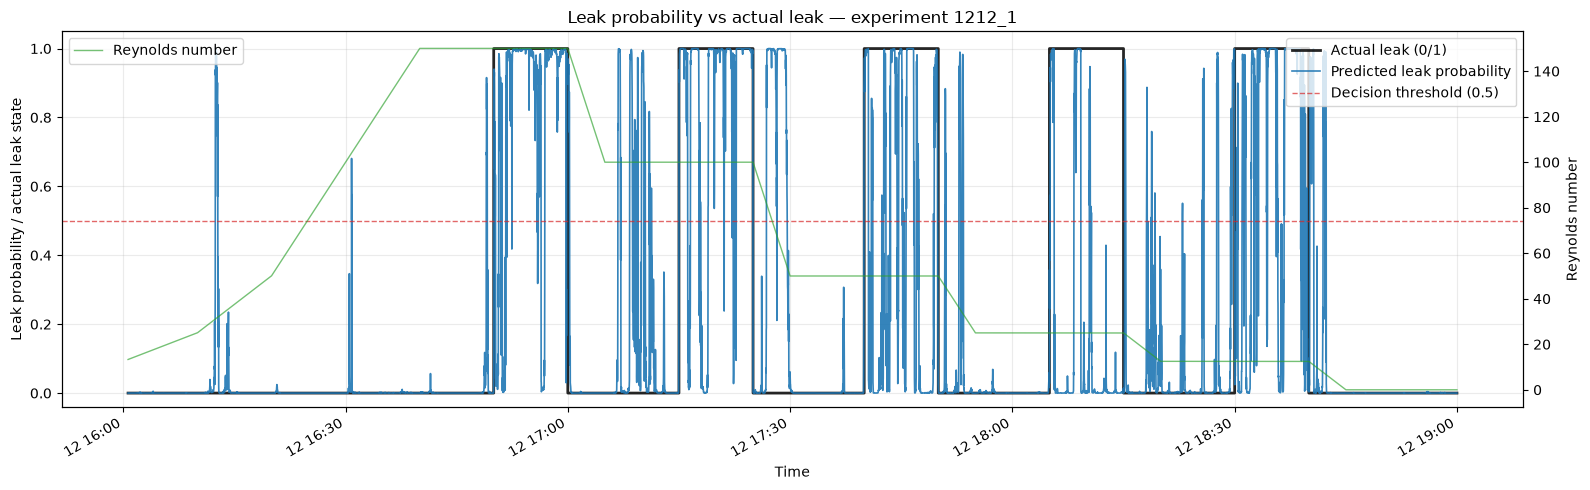

Saved figure: /home/ubuntu/notebooks/Leak_Detection/results/validation_outputs/1212_1_leak_probability_vs_actual.png


In [13]:
fig, ax = plt.subplots(figsize=(16, 5))
x = results["datetime"]
ax.step(x, results["true_leak"], where="post", linewidth=2.0,
        color="black", alpha=0.85, label="Actual leak (0/1)")
ax.plot(x, results["predicted_leak_probability"], color="tab:blue",
        linewidth=1.2, alpha=0.9, label="Predicted leak probability")
ax2 = ax.twinx()
ax2.plot(
    x, results["Reynolds"],
    color="tab:green", alpha=0.65,
    linewidth=1, label="Reynolds number"
)
ax2.set_ylabel("Reynolds number")
ax2.legend(loc="upper left")
ax.axhline(THRESHOLD, color="tab:red", linestyle="--", linewidth=1,
           alpha=0.7, label=f"Decision threshold ({THRESHOLD:g})")
ax.set(title=f"Leak probability vs actual leak — experiment {EXPERIMENT}",
       xlabel="Time", ylabel="Leak probability / actual leak state", ylim=(-0.04, 1.05))
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
plot_path = OUTPUT_DIR / f"{EXPERIMENT}_leak_probability_vs_actual.png"
fig.savefig(plot_path, dpi=170, bbox_inches="tight")
plt.show()
print("Saved figure:", plot_path)

## 6. Save validation predictions and metrics

CSV contains timestamp, actual label, predicted probability, and thresholded prediction for every window endpoint. Metrics are descriptive because this experiment was used by the author for validation/model selection, and windows overlap heavily. **Do not interpret 10,000+ windows as independent experiments.**

In [12]:
csv_path = OUTPUT_DIR / f"{EXPERIMENT}_leak_validation_predictions.csv"
results.to_csv(csv_path, index=False)
y = results["true_leak"].to_numpy(dtype=int)
p = results["predicted_leak_probability"].to_numpy(dtype=float)
y_hat = (p >= THRESHOLD).astype(int)
metrics = {
    "experiment": EXPERIMENT,
    "num_windows": len(results),
    "window_size": WINDOW_SIZE,
    "threshold": THRESHOLD,
    "positive_rate": float(y.mean()),
    "accuracy": accuracy_score(y, y_hat),
    "precision": precision_score(y, y_hat, zero_division=0),
    "recall": recall_score(y, y_hat, zero_division=0),
    "f1": f1_score(y, y_hat, zero_division=0),
    "brier_score": brier_score_loss(y, p),
    "tn": int(confusion_matrix(y, y_hat, labels=[0, 1])[0, 0]),
    "fp": int(confusion_matrix(y, y_hat, labels=[0, 1])[0, 1]),
    "fn": int(confusion_matrix(y, y_hat, labels=[0, 1])[1, 0]),
    "tp": int(confusion_matrix(y, y_hat, labels=[0, 1])[1, 1]),
}
if len(np.unique(y)) == 2:
    metrics["average_precision"] = average_precision_score(y, p)
    metrics["roc_auc"] = roc_auc_score(y, p)
else:
    metrics["average_precision"] = np.nan
    metrics["roc_auc"] = np.nan
metrics_df = pd.DataFrame([metrics])
metrics_path = OUTPUT_DIR / f"{EXPERIMENT}_leak_validation_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print(metrics_df.T.to_string(header=False))
print("\nSaved predictions:", csv_path)
print("Saved metrics:", metrics_path)
print("Saved figure:", plot_path)

experiment           1212_1
num_windows           10762
window_size              40
threshold               0.5
positive_rate      0.278759
accuracy           0.838692
precision          0.785199
recall                 0.58
f1                 0.667178
brier_score        0.144287
tn                     7286
fp                      476
fn                     1260
tp                     1740
average_precision   0.76507
roc_auc            0.891777

Saved predictions: /home/ubuntu/notebooks/Leak_Detection/results/validation_outputs/1212_1_leak_validation_predictions.csv
Saved metrics: /home/ubuntu/notebooks/Leak_Detection/results/validation_outputs/1212_1_leak_validation_metrics.csv
Saved figure: /home/ubuntu/notebooks/Leak_Detection/results/validation_outputs/1212_1_leak_probability_vs_actual.png


## Interpretation and limitations

- A good result should show probability near **1 during leaks** and near **0 outside leaks**. The model is not forced to produce such an ideal square wave.
- Predictions begin at the 40th observation because each prediction needs a complete window.
- The original notebook's model-selection threshold is not recoverable from the supplied `.pt` state dictionaries. The default `0.5` used here can be changed in the configuration cell, but choosing a threshold using this validation run and reporting the resulting F1 on the same run will be optimistic.
- `1212_1` was used as validation during model development. For an untouched test, obtain the four `1207_1` CSV files, configure their coordinates (provided in the original notebook), and run the same pipeline without tuning.
- This notebook uses only `leak_detect_baseline.pt` and `leak_detect_residual.pt`; `re_pred.pt` is not part of the original two-stage inference function.